# Support Vector Machines (SVM)

## Project overview
Study Support Vector Machines for classification and explore how margins and kernels can create decision boundaries.

## Objectives
- Prepare features for SVM modeling
- Fit an SVM classifier
- Explore linear and nonlinear decision boundaries
- Understand the influence of regularization and kernel settings

## Tools and approach
- **Language:** Python
- **Core libraries:** pandas, NumPy, Matplotlib/Seaborn, and scikit-learn or TensorFlow/Keras where used in the notebook
- **Workflow:** data inspection and preparation, model/technique exploration, and evaluation or visualization

**Methods covered:** Support Vector Classifier, feature scaling where appropriate, and visual exploration of margins/decision boundaries.

> **Reproducibility note:** Run the notebook from top to bottom. Dataset paths may need to be selected or updated to match the Kaggle dataset attached to your notebook. Results can vary with data splits, random seeds, and library versions.


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/iris")

print("Path to dataset files:", path)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

Path to dataset files: /kaggle/input/iris


In [2]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as pl
import seaborn as sns

In [3]:
df  =  pd.read_csv('/kaggle/input/iris/Iris.csv')

In [5]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)


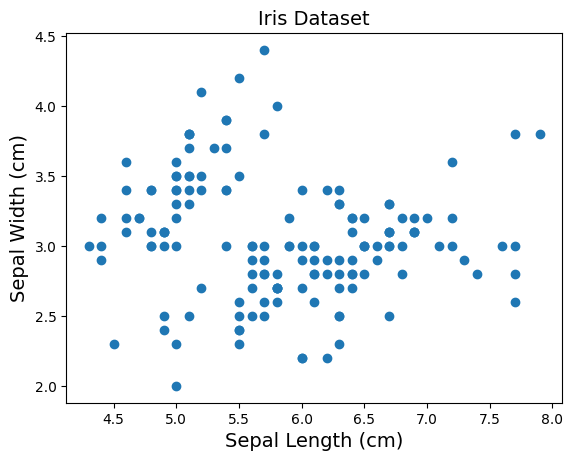

In [6]:
plt.scatter(df['SepalLengthCm'], df['SepalWidthCm'])
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Iris Dataset')

plt.show()


In [7]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "svm"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

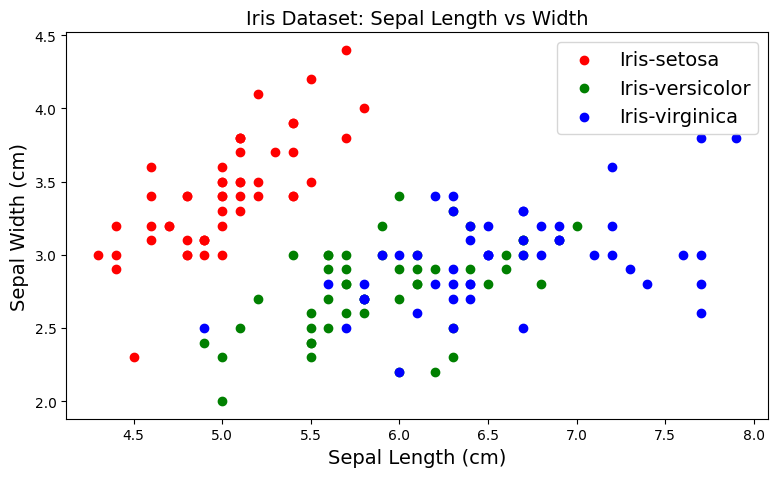

In [8]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

IMAGES_PATH = Path() / "images" / "svm"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)
plt.figure(figsize=(8, 5))

species = df['Species'].unique()
colors = ['red', 'green', 'blue']

for sp, color in zip(species, colors):
    subset = df[df['Species'] == sp]
    plt.scatter(subset['SepalLengthCm'], subset['SepalWidthCm'], label=sp, color=color)
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Iris Dataset: Sepal Length vs Width')
plt.legend()
save_fig("iris_sepal_scatter")
plt.show()


# Linear SVM Classification

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.svm import SVC

X = df[["PetalLengthCm", "PetalWidthCm"]].values
y = df["Species"].factorize()[0]
setosa_or_versicolor = (y == 0) | (y == 1)
X = X[setosa_or_versicolor]
y = y[setosa_or_versicolor]
IMAGES_PATH = Path() / "images" / "svm"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)
svm_clf = SVC(kernel="linear", C=1e100)
svm_clf.fit(X, y)
x0 = np.linspace(0, 5.5, 200)
pred_1 = 5 * x0 - 20
pred_2 = x0 - 1.8
pred_3 = 0.1 * x0 + 0.5
def plot_svc_decision_boundary(svm_clf, xmin, xmax):
    w = svm_clf.coef_[0]
    b = svm_clf.intercept_[0]

    x0 = np.linspace(xmin, xmax, 200)
    decision_boundary = -w[0]/w[1] * x0 - b/w[1]
    margin = 1 / w[1]
    gutter_up = decision_boundary + margin
    gutter_down = decision_boundary - margin
    svs = svm_clf.support_vectors_

    plt.plot(x0, decision_boundary, "k-", linewidth=2, zorder=-2)
    plt.plot(x0, gutter_up, "k--", linewidth=2, zorder=-2)
    plt.plot(x0, gutter_down, "k--", linewidth=2, zorder=-2)
    plt.scatter(svs[:, 0], svs[:, 1], s=180, facecolors='#AAA', zorder=-1)

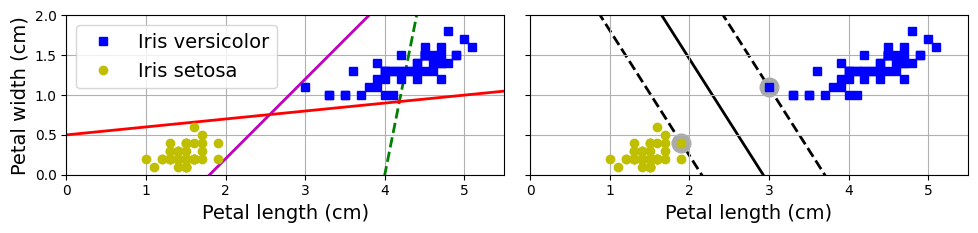

In [11]:
fig, axes = plt.subplots(ncols=2, figsize=(10, 2.7), sharey=True)
plt.sca(axes[0])
plt.plot(x0, pred_1, "g--", linewidth=2)
plt.plot(x0, pred_2, "m-", linewidth=2)
plt.plot(x0, pred_3, "r-", linewidth=2)
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs", label="Iris versicolor")
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo", label="Iris setosa")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend(loc="upper left")
plt.axis([0, 5.5, 0, 2])
plt.gca().set_aspect("equal")
plt.grid()
plt.sca(axes[1])
plot_svc_decision_boundary(svm_clf, 0, 5.5)
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs")
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo")
plt.xlabel("Petal length (cm)")
plt.axis([0, 5.5, 0, 2])
plt.gca().set_aspect("equal")
plt.grid()
save_fig("large_margin_classification_plot")
plt.show()

In [12]:
from sklearn.datasets import load_iris
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = (iris.target == 2) # Iris virginica
svm_clf = make_pipeline(StandardScaler(),
LinearSVC(C=1, random_state=42))
svm_clf.fit(X, y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearsvc', LinearSVC(C=1, random_state=42))])

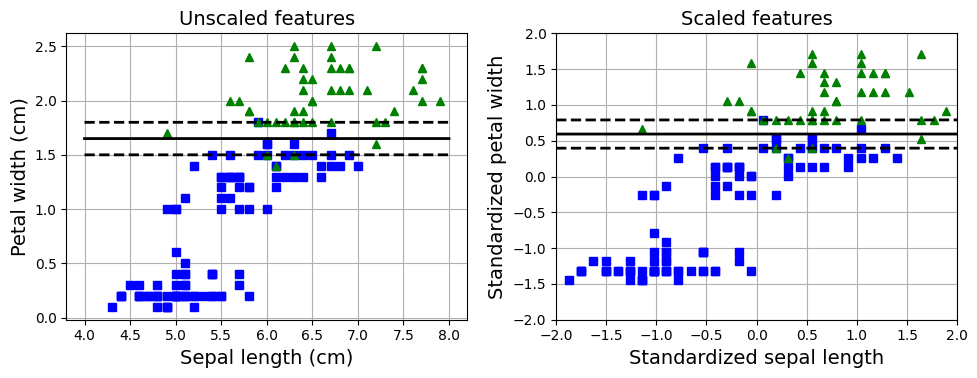

In [13]:
def plot_svc_decision_boundary(svm_clf, xmin, xmax):
    w = svm_clf.coef_[0]
    b = svm_clf.intercept_[0]

    x0 = np.linspace(xmin, xmax, 200)
    decision_boundary = -w[0] / w[1] * x0 - b / w[1]

    margin = 1 / w[1]
    gutter_up = decision_boundary + margin
    gutter_down = decision_boundary - margin

    plt.plot(x0, decision_boundary, "k-", linewidth=2)
    plt.plot(x0, gutter_up, "k--", linewidth=2)
    plt.plot(x0, gutter_down, "k--", linewidth=2)

X = df[['SepalLengthCm', 'PetalWidthCm']].values
y = (df['Species'] == 'Iris-virginica').astype(int)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
svm_clf = SVC(kernel="linear", C=100)
svm_clf.fit(X, y)

plt.plot(X[y==0, 0], X[y==0, 1], "bs")
plt.plot(X[y==1, 0], X[y==1, 1], "g^")
plot_svc_decision_boundary(svm_clf, 4, 8)

plt.xlabel("Sepal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Unscaled features")
plt.grid()
plt.subplot(1, 2, 2)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

svm_clf_scaled = SVC(kernel="linear", C=100)
svm_clf_scaled.fit(X_scaled, y)

plt.plot(X_scaled[y==0, 0], X_scaled[y==0, 1], "bs")
plt.plot(X_scaled[y==1, 0], X_scaled[y==1, 1], "g^")
plot_svc_decision_boundary(svm_clf_scaled, -2, 2)

plt.axis([-2, 2, -2, 2])
plt.xlabel("Standardized sepal length")
plt.ylabel("Standardized petal width")
plt.title("Scaled features")
plt.grid()

plt.tight_layout()
plt.show()


In [14]:
from sklearn.svm import SVC
def plot_svc_decision_boundary(svm_clf, xmin, xmax):
    w = svm_clf.coef_[0]
    b = svm_clf.intercept_[0]

    x0 = np.linspace(xmin, xmax, 200)
    decision_boundary = -w[0] / w[1] * x0 - b / w[1]

    margin = 1 / w[1]
    gutter_up = decision_boundary + margin
    gutter_down = decision_boundary - margin

    plt.plot(x0, decision_boundary, "k-", linewidth=2)
    plt.plot(x0, gutter_up, "k--", linewidth=2)
    plt.plot(x0, gutter_down, "k--", linewidth=2)
X = df[['PetalLengthCm', 'PetalWidthCm']].values
y = (df['Species'] == 'Iris-virginica').astype(int)
X_outliers = np.array([[3.4, 1.3], [3.2, 0.8]])
y_outliers = np.array([0, 0])

Xo1 = np.concatenate([X, X_outliers[:1]], axis=0)
yo1 = np.concatenate([y, y_outliers[:1]], axis=0)

Xo2 = np.concatenate([X, X_outliers[1:]], axis=0)
yo2 = np.concatenate([y, y_outliers[1:]], axis=0)

svm_clf2 = SVC(kernel="linear", C=10**9)
svm_clf2.fit(Xo2, yo2)


SVC(C=1000000000, kernel='linear')

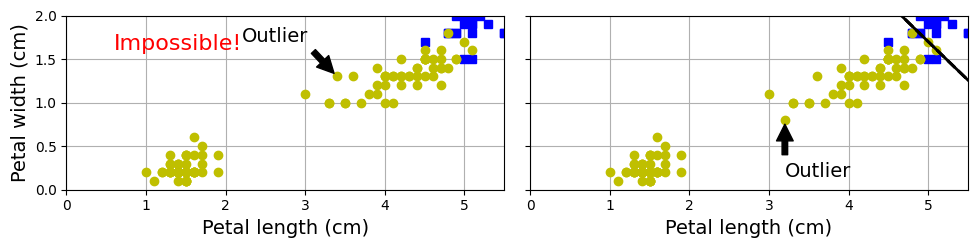

In [15]:
fig, axes = plt.subplots(ncols=2, figsize=(10, 2.7), sharey=True)
plt.sca(axes[0])
plt.plot(Xo1[yo1==1, 0], Xo1[yo1==1, 1], "bs")
plt.plot(Xo1[yo1==0, 0], Xo1[yo1==0, 1], "yo")

plt.text(0.6, 1.6, "Impossible!", color="red", fontsize=16)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")

plt.annotate(
    "Outlier",
    xy=(X_outliers[0][0], X_outliers[0][1]),
    xytext=(2.2, 1.7),
    arrowprops=dict(facecolor='black', shrink=0.1),
)

plt.axis([0, 5.5, 0, 2])
plt.grid()
plt.sca(axes[1])
plt.plot(Xo2[yo2==1, 0], Xo2[yo2==1, 1], "bs")
plt.plot(Xo2[yo2==0, 0], Xo2[yo2==0, 1], "yo")

plot_svc_decision_boundary(svm_clf2, 0, 5.5)

plt.xlabel("Petal length (cm)")
plt.annotate(
    "Outlier",
    xy=(X_outliers[1][0], X_outliers[1][1]),
    xytext=(3.2, 0.15),
    arrowprops=dict(facecolor='black', shrink=0.1),
)

plt.axis([0, 5.5, 0, 2])
plt.grid()

plt.tight_layout()
plt.show()


In [16]:
X = df[['PetalLengthCm', 'PetalWidthCm']].values
y = (df['Species'] == 'Iris-virginica')
svm_clf = make_pipeline(
    StandardScaler(),
    LinearSVC(C=1, dual=True, random_state=42)
)

svm_clf.fit(X, y)
X_new = np.array([[5.5, 1.7],
                  [5.0, 1.5]])

svm_clf.predict(X_new)
svm_clf.decision_function(X_new)


array([ 0.66187855, -0.22004654])

In [17]:
def plot_svc_decision_boundary(svm_clf, xmin, xmax):
    w = svm_clf.coef_[0]
    b = svm_clf.intercept_[0]

    x0 = np.linspace(xmin, xmax, 200)
    decision_boundary = -w[0] / w[1] * x0 - b / w[1]

    margin = 1 / w[1]
    gutter_up = decision_boundary + margin
    gutter_down = decision_boundary - margin

    plt.plot(x0, decision_boundary, "k-", linewidth=2)
    plt.plot(x0, gutter_up, "k--", linewidth=2)
    plt.plot(x0, gutter_down, "k--", linewidth=2)


def save_fig(fig_id):
    plt.savefig(fig_id + ".png", dpi=300, bbox_inches="tight")
scaler = StandardScaler()

svm_clf1 = LinearSVC(C=1, max_iter=10_000, dual=True, random_state=42)
svm_clf2 = LinearSVC(C=100, max_iter=10_000, dual=True, random_state=42)

scaled_svm_clf1 = make_pipeline(scaler, svm_clf1)
scaled_svm_clf2 = make_pipeline(scaler, svm_clf2)

scaled_svm_clf1.fit(X, y)
scaled_svm_clf2.fit(X, y)
b1 = svm_clf1.decision_function([-scaler.mean_ / scaler.scale_])
b2 = svm_clf2.decision_function([-scaler.mean_ / scaler.scale_])

w1 = svm_clf1.coef_[0] / scaler.scale_
w2 = svm_clf2.coef_[0] / scaler.scale_

svm_clf1.intercept_ = np.array([b1])
svm_clf2.intercept_ = np.array([b2])
svm_clf1.coef_ = np.array([w1])
svm_clf2.coef_ = np.array([w2])



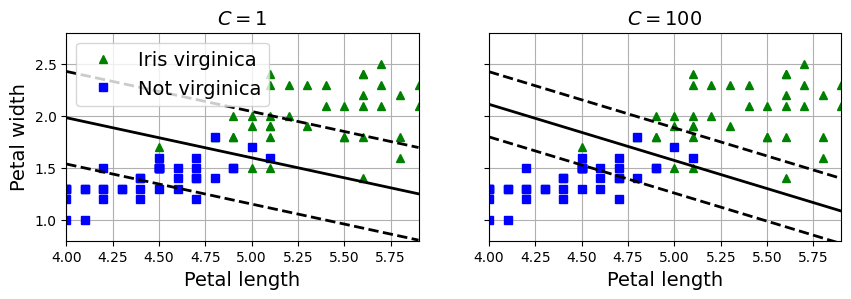

In [19]:
t = y * 2 - 1

support_vectors_idx1 = (t * (X.dot(w1) + b1) < 1)
support_vectors_idx2 = (t * (X.dot(w2) + b2) < 1)

svm_clf1.support_vectors_ = X[support_vectors_idx1]
svm_clf2.support_vectors_ = X[support_vectors_idx2]
fig, axes = plt.subplots(ncols=2, figsize=(10, 2.7), sharey=True)

plt.sca(axes[0])
plt.plot(X[y==1][:,0], X[y==1][:,1], "g^", label="Iris virginica")
plt.plot(X[y==0][:,0], X[y==0][:,1], "bs", label="Not virginica")
plot_svc_decision_boundary(svm_clf1, 4, 5.9)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper left")
plt.title(f"$C = {svm_clf1.C}$")
plt.axis([4, 5.9, 0.8, 2.8])
plt.grid()

plt.sca(axes[1])
plt.plot(X[y==1][:,0], X[y==1][:,1], "g^")
plt.plot(X[y==0][:,0], X[y==0][:,1], "bs")
plot_svc_decision_boundary(svm_clf2, 4, 5.99)
plt.xlabel("Petal length")
plt.title(f"$C = {svm_clf2.C}$")
plt.axis([4, 5.9, 0.8, 2.8])
plt.grid()

save_fig("regularization_plot")
plt.show()


# Nonlinear SVM Classification

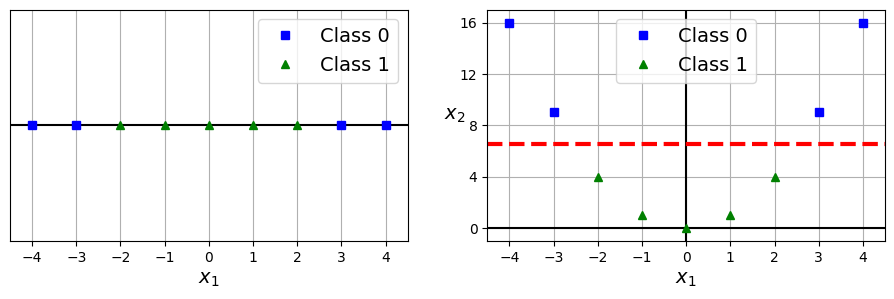

In [20]:
def save_fig(fig_id, tight_layout=True):
    if tight_layout:
        plt.tight_layout()
    plt.savefig(fig_id + ".png", dpi=300)
X1D = np.linspace(-4, 4, 9).reshape(-1, 1)
X2D = np.c_[X1D, X1D**2]
y = np.array([0, 0, 1, 1, 1, 1, 1, 0, 0])

plt.figure(figsize=(10, 3))
plt.subplot(121)
plt.grid(True)
plt.axhline(y=0, color='k')
plt.plot(X1D[:, 0][y==0], np.zeros(4), "bs", label="Class 0")
plt.plot(X1D[:, 0][y==1], np.zeros(5), "g^", label="Class 1")
plt.gca().get_yaxis().set_ticks([])
plt.xlabel("$x_1$")
plt.axis([-4.5, 4.5, -0.2, 0.2])
plt.legend()
plt.subplot(122)
plt.grid(True)
plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.plot(X2D[:, 0][y==0], X2D[:, 1][y==0], "bs", label="Class 0")
plt.plot(X2D[:, 0][y==1], X2D[:, 1][y==1], "g^", label="Class 1")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$", rotation=0)
plt.gca().get_yaxis().set_ticks([0, 4, 8, 12, 16])
plt.plot([-4.5, 4.5], [6.5, 6.5], "r--", linewidth=3)  # example threshold
plt.axis([-4.5, 4.5, -1, 17])
plt.legend()

plt.subplots_adjust(right=1)
save_fig("higher_dimensions_plot", tight_layout=False)
plt.show()


In [21]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

X, y = make_moons(n_samples=100, noise=0.15, random_state=42)
poly = PolynomialFeatures(degree=3)
X_poly = poly.fit_transform(X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_poly)
svm_clf = LinearSVC(C=10, max_iter=10_000, dual=True, random_state=42)
svm_clf.fit(X_scaled, y)
X_new = X[:5]
X_new_poly = poly.transform(X_new)
X_new_scaled = scaler.transform(X_new_poly)
predictions = svm_clf.predict(X_new_scaled)
predictions


array([1, 1, 1, 0, 0])

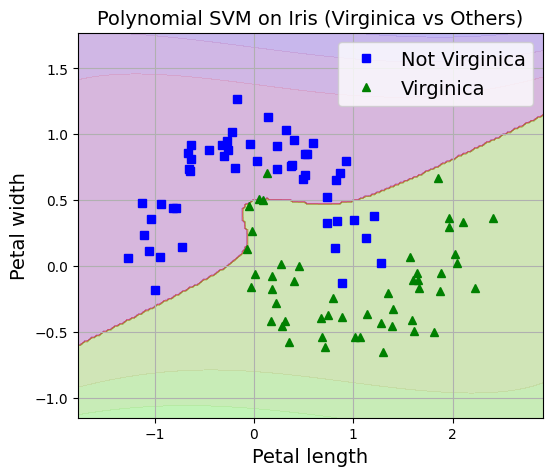

In [22]:
polynomial_svm_clf = make_pipeline(
    StandardScaler(),
    SVC(kernel='poly', degree=3, C=5)
)
polynomial_svm_clf.fit(X, y)
def plot_dataset(X, y, axes):
    plt.plot(X[y==0, 0], X[y==0, 1], "bs", label="Not Virginica")
    plt.plot(X[y==1, 0], X[y==1, 1], "g^", label="Virginica")
    plt.axis(axes)
    plt.grid(True)
    plt.xlabel("Petal length")
    plt.ylabel("Petal width")
    plt.legend()

def plot_predictions(clf
                     , axes):
    x0s = np.linspace(axes[0], axes[1], 200)
    x1s = np.linspace(axes[2], axes[3], 200)
    x0, x1 = np.meshgrid(x0s, x1s)
    X_grid = np.c_[x0.ravel(), x1.ravel()]
    y_pred = clf.predict(X_grid).reshape(x0.shape)
    y_decision = clf.decision_function(X_grid).reshape(x0.shape)
    plt.contourf(x0, x1, y_pred, cmap=plt.cm.brg, alpha=0.2)
    plt.contourf(x0, x1, y_decision, cmap=plt.cm.brg, alpha=0.1)
axes = [X[:,0].min()-0.5, X[:,0].max()+0.5, X[:,1].min()-0.5, X[:,1].max()+0.5]

plt.figure(figsize=(6,5))
plot_predictions(polynomial_svm_clf, axes)
plot_dataset(X, y, axes)
plt.title("Polynomial SVM on Iris (Virginica vs Others)")
plt.show()


# Polynomial Kernel

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
def plot_dataset(X, y, axes):
    plt.plot(X[y==0, 0], X[y==0, 1], "bs")
    plt.plot(X[y==1, 0], X[y==1, 1], "g^")
    plt.axis(axes)
    plt.grid(True)
    plt.xlabel("Petal length")
    plt.ylabel("Petal width")

def plot_predictions(clf, axes, resolution=50):
    xx, yy = np.meshgrid(
        np.linspace(axes[0], axes[1], resolution),
        np.linspace(axes[2], axes[3], resolution)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = clf.predict(grid).reshape(xx.shape)
    plt.contourf(xx, yy, Z, cmap=plt.cm.brg, alpha=0.2)

models = [
    ("degree=3, coef0=1, C=5",
     make_pipeline(StandardScaler(),
                   SVC(kernel="poly", degree=3, coef0=1, C=5))),
    
    ("degree=10, coef0=100, C=5",
     make_pipeline(StandardScaler(),
                   SVC(kernel="poly", degree=10, coef0=100, C=5)))
]

for _, model in models:
    model.fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), sharey=True)

bounds = [
    X[:,0].min() - 0.5, X[:,0].max() + 0.5,
    X[:,1].min() - 0.5, X[:,1].max() + 0.5
]

for ax, (title, clf) in zip(axes, models):
    plt.sca(ax)
    plot_predictions(clf, bounds)
    plot_dataset(X, y, bounds)
    ax.set_title(title)

plt.tight_layout()
plt.show()


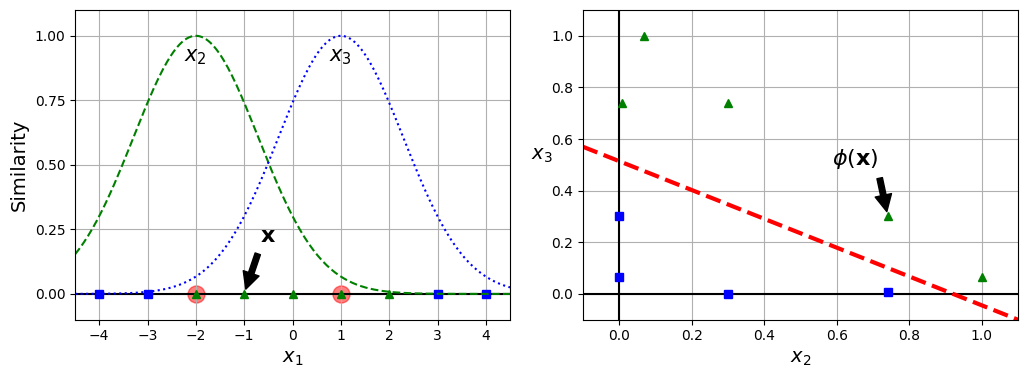

In [24]:
def gaussian_rbf(x, landmark, gamma):
    return np.exp(-gamma * np.linalg.norm(x - landmark, axis=1)**2)

gamma = 0.3

x1s = np.linspace(-4.5, 4.5, 200).reshape(-1, 1)
x2s = gaussian_rbf(x1s, -2, gamma)
x3s = gaussian_rbf(x1s, 1, gamma)

XK = np.c_[gaussian_rbf(X1D, -2, gamma), gaussian_rbf(X1D, 1, gamma)]
yk = np.array([0, 0, 1, 1, 1, 1, 1, 0, 0])

plt.figure(figsize=(10.5, 4))

plt.subplot(121)
plt.grid(True)
plt.axhline(y=0, color='k')
plt.scatter(x=[-2, 1], y=[0, 0], s=150, alpha=0.5, c="red")
plt.plot(X1D[:, 0][yk==0], np.zeros(4), "bs")
plt.plot(X1D[:, 0][yk==1], np.zeros(5), "g^")
plt.plot(x1s, x2s, "g--")
plt.plot(x1s, x3s, "b:")
plt.gca().get_yaxis().set_ticks([0, 0.25, 0.5, 0.75, 1])
plt.xlabel("$x_1$")
plt.ylabel("Similarity")
plt.annotate(
    r'$\mathbf{x}$',
    xy=(X1D[3, 0], 0),
    xytext=(-0.5, 0.20),
    ha="center",
    arrowprops=dict(facecolor='black', shrink=0.1),
    fontsize=16,
)
plt.text(-2, 0.9, "$x_2$", ha="center", fontsize=15)
plt.text(1, 0.9, "$x_3$", ha="center", fontsize=15)
plt.axis([-4.5, 4.5, -0.1, 1.1])

plt.subplot(122)
plt.grid(True)
plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.plot(XK[:, 0][yk==0], XK[:, 1][yk==0], "bs")
plt.plot(XK[:, 0][yk==1], XK[:, 1][yk==1], "g^")
plt.xlabel("$x_2$")
plt.ylabel("$x_3$  ", rotation=0)
plt.annotate(
    r'$\phi\left(\mathbf{x}\right)$',
    xy=(XK[3, 0], XK[3, 1]),
    xytext=(0.65, 0.50),
    ha="center",
    arrowprops=dict(facecolor='black', shrink=0.1),
    fontsize=16,
)
plt.plot([-0.1, 1.1], [0.57, -0.1], "r--", linewidth=3)
plt.axis([-0.1, 1.1, -0.1, 1.1])
    
plt.subplots_adjust(right=1)

save_fig("kernel_method_plot")
plt.show()

# Gaussian RBF Kernel

In [25]:
rbf_kernel_svm_clf = make_pipeline(StandardScaler(),
                                   SVC(kernel="rbf", gamma=5, C=0.001))
rbf_kernel_svm_clf.fit(X, y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(C=0.001, gamma=5))])

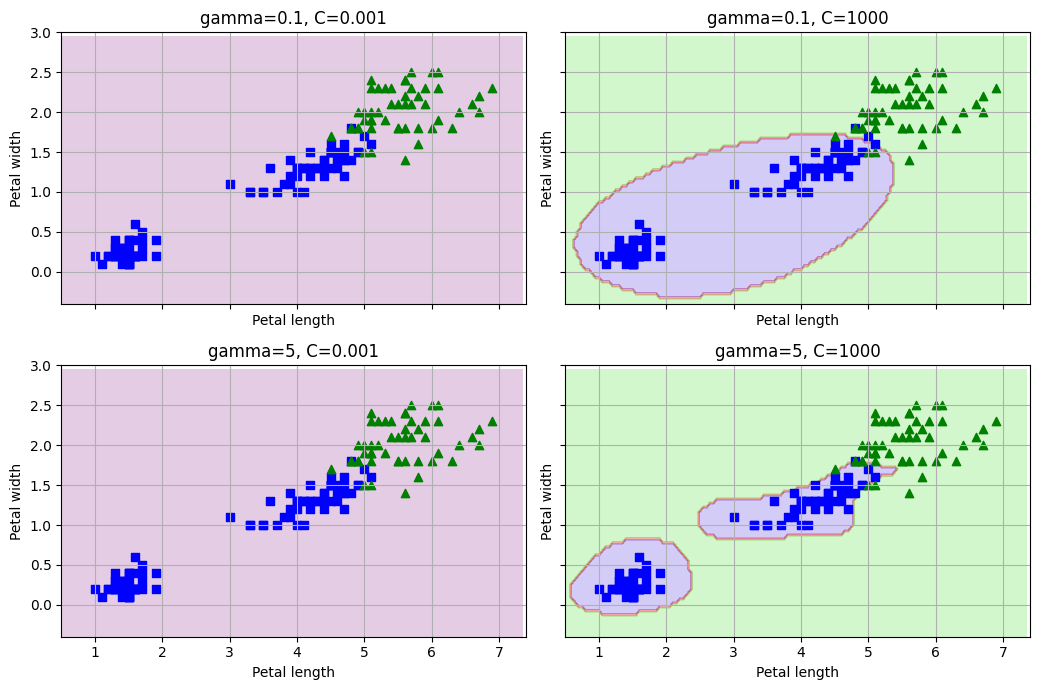

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def plot_data(X, y, limits):
    plt.scatter(X[y==0,0], X[y==0,1], c='b', marker='s')
    plt.scatter(X[y==1,0], X[y==1,1], c='g', marker='^')
    plt.axis(limits)
    plt.grid(True)
    plt.xlabel("Petal length")
    plt.ylabel("Petal width")

def plot_boundary(model, limits, step=0.05):
    x0, x1 = np.meshgrid(
        np.arange(limits[0], limits[1], step),
        np.arange(limits[2], limits[3], step)
    )
    grid = np.c_[x0.ravel(), x1.ravel()]
    preds = model.predict(grid).reshape(x0.shape)
    plt.contourf(x0, x1, preds, alpha=0.2, cmap=plt.cm.brg)

params = [
    (0.1, 0.001),
    (0.1, 1000),
    (5,   0.001),
    (5,   1000)
]

models = []
for gamma, C in params:
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", gamma=gamma, C=C)
    )
    model.fit(X, y)
    models.append(model)

x_min, x_max = X[:,0].min() - 0.5, X[:,0].max() + 0.5
y_min, y_max = X[:,1].min() - 0.5, X[:,1].max() + 0.5
limits = [x_min, x_max, y_min, y_max]

fig, axes = plt.subplots(2, 2, figsize=(10.5, 7), sharex=True, sharey=True)

for idx, (ax, model) in enumerate(zip(axes.ravel(), models)):
    plt.sca(ax)
    plot_boundary(model, limits)
    plot_data(X, y, limits)
    g, c = params[idx]
    ax.set_title(f"gamma={g}, C={c}")

plt.tight_layout()
plt.show()


# SVM Regression


In [27]:
from sklearn.svm import LinearSVR
np.random.seed(42)
X = 2 * np.random.rand(50, 1)
y = 4 + 3 * X[:, 0] + np.random.randn(50)

svm_reg = make_pipeline(StandardScaler(),
                        LinearSVR(epsilon=0.5, dual=True, random_state=42))
svm_reg.fit(X, y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearsvr',
                 LinearSVR(dual=True, epsilon=0.5, random_state=42))])

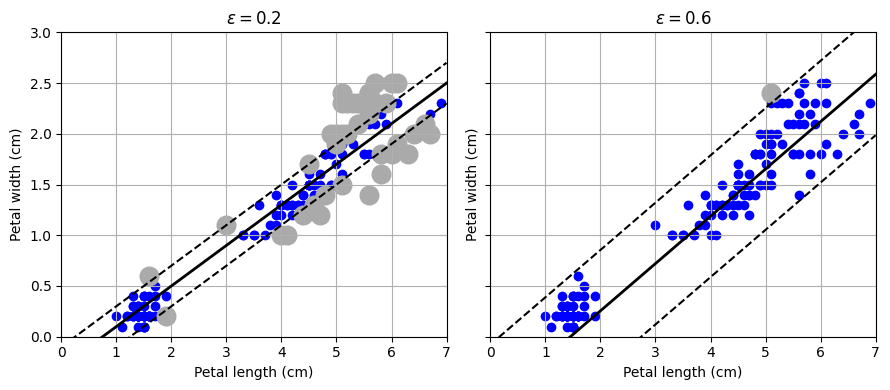

In [8]:
def find_support_vectors(model, X, y):
    y_pred = model.predict(X)
    eps = model[-1].epsilon
    return np.where(np.abs(y - y_pred) >= eps)[0]

def plot_svm_regression(model, X, y, axes):
    x_new = np.linspace(axes[0], axes[1], 200).reshape(-1, 1)
    y_pred = model.predict(x_new)
    eps = model[-1].epsilon

    plt.plot(x_new, y_pred, "k-", linewidth=2)
    plt.plot(x_new, y_pred + eps, "k--")
    plt.plot(x_new, y_pred - eps, "k--")

    plt.scatter(X, y, color="blue")
    plt.scatter(X[model.support_], y[model.support_],
                s=180, facecolors="#AAA")

    plt.axis(axes)
    plt.xlabel("Petal length (cm)")
    plt.ylabel("Petal width (cm)")
    plt.grid(True)

svm_reg1 = make_pipeline(
    StandardScaler(),
    LinearSVR(epsilon=0.2, random_state=42)
)

svm_reg2 = make_pipeline(
    StandardScaler(),
    LinearSVR(epsilon=0.6, random_state=42)
)

svm_reg1.fit(X, y)
svm_reg2.fit(X, y)

svm_reg1.support_ = find_support_vectors(svm_reg1, X, y)
svm_reg2.support_ = find_support_vectors(svm_reg2, X, y)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

plt.sca(axes[0])
plot_svm_regression(svm_reg1, X, y, [0, 7, 0, 3])
plt.title(r"$\epsilon = 0.2$")

plt.sca(axes[1])
plot_svm_regression(svm_reg2, X, y, [0, 7, 0, 3])
plt.title(r"$\epsilon = 0.6$")

plt.tight_layout()
plt.show()


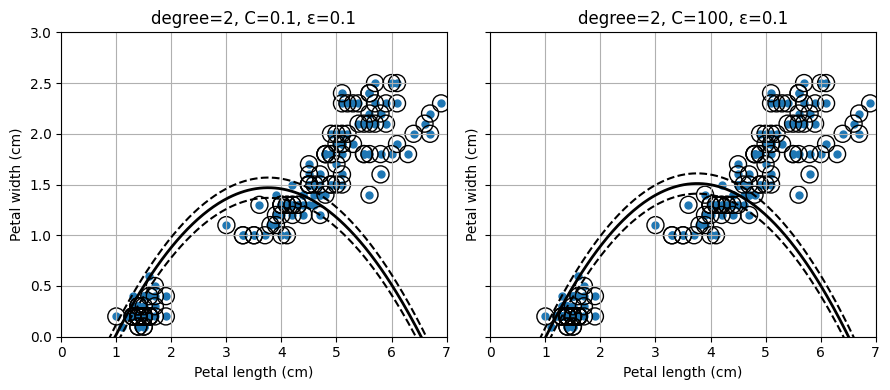

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data[:, 2:3]  
y = iris.data[:, 3]   

def find_support_vectors(model, X, y):
    y_pred = model.predict(X)
    eps = model[-1].epsilon
    return np.where(np.abs(y - y_pred) >= eps)[0]

def plot_svm_regression(model, X, y, axes):
    x_new = np.linspace(axes[0], axes[1], 300).reshape(-1, 1)
    y_pred = model.predict(x_new)
    eps = model[-1].epsilon

    plt.plot(x_new, y_pred, "k-", linewidth=2)
    plt.plot(x_new, y_pred + eps, "k--")
    plt.plot(x_new, y_pred - eps, "k--")

    plt.scatter(X, y, s=25)
    plt.scatter(X[model.support_], y[model.support_],
                s=150, facecolors="none", edgecolors="k")

    plt.axis(axes)
    plt.xlabel("Petal length (cm)")
    plt.ylabel("Petal width (cm)")
    plt.grid(True)

svr_low_C = make_pipeline(
    StandardScaler(),
    SVR(kernel="poly", degree=2, C=0.1, epsilon=0.1)
)

svr_high_C = make_pipeline(
    StandardScaler(),
    SVR(kernel="poly", degree=2, C=100, epsilon=0.1)
)


svr_low_C.fit(X, y)
svr_high_C.fit(X, y)

# Custom "support vectors" (epsilon violations)
svr_low_C.support_ = find_support_vectors(svr_low_C, X, y)
svr_high_C.support_ = find_support_vectors(svr_high_C, X, y)

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

plt.sca(axes[0])
plot_svm_regression(svr_low_C, X, y, [0, 7, 0, 3])
plt.title("degree=2, C=0.1, ε=0.1")

plt.sca(axes[1])
plot_svm_regression(svr_high_C, X, y, [0, 7, 0, 3])
plt.title("degree=2, C=100, ε=0.1")

plt.tight_layout()
plt.show()


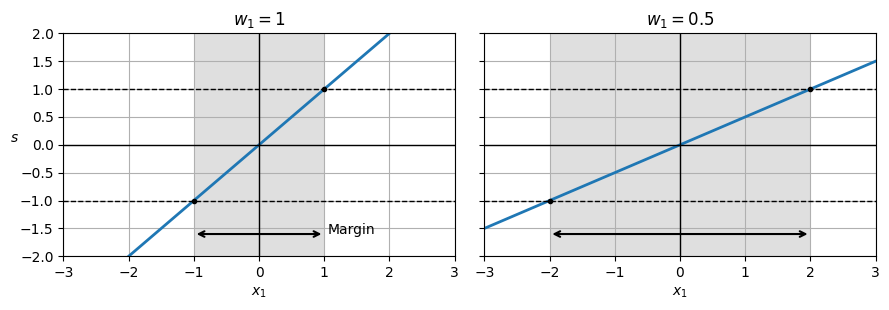

In [6]:

from matplotlib.patches import Rectangle

def draw_margin_plot(w, ax, show_ylabel=True):
    x = np.linspace(-3, 3, 300)
    score = w * x
    margin = 1 / w

    ax.plot(x, score, linewidth=2)
    ax.axhline(0, color='black', linewidth=1)
    ax.axvline(0, color='black', linewidth=1)

    # Margin region
    ax.add_patch(Rectangle(
        (-margin, -2), 2 * margin, 4,
        facecolor='gray', alpha=0.25
    ))

    # Margin lines
    ax.plot(x, np.ones_like(x), "k--", linewidth=1)
    ax.plot(x, -np.ones_like(x), "k--", linewidth=1)

    # Margin points
    ax.plot([margin, -margin], [1, -1], "k.")

    # Arrow
    ax.annotate(
        '', xy=(-margin, -1.6), xytext=(margin, -1.6),
        arrowprops=dict(arrowstyle="<->", linewidth=1.5)
    )

    ax.set_xlim(-3, 3)
    ax.set_ylim(-2, 2)
    ax.set_xlabel("$x_1$")
    ax.set_title(f"$w_1 = {w}$")

    if show_ylabel:
        ax.set_ylabel("$s$", rotation=0)
        ax.text(1.05, -1.6, "Margin", ha="left")

    ax.grid(True)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)

draw_margin_plot(w=1, ax=axes[0], show_ylabel=True)
draw_margin_plot(w=0.5, ax=axes[1], show_ylabel=False)

plt.tight_layout()
plt.show()


In [11]:
print(df.head())

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(".", f"{fig_id}.{fig_extension}")
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)
    print(f"Figure saved as {path}")

s = np.linspace(-2.5, 2.5, 200)

hinge_pos = np.maximum(0, 1 - s)   # t = +1
hinge_neg = np.maximum(0, 1 + s)   # t = -1

titles = (
    r"Hinge loss = $\max(0, 1 - s\,t)$",
    "Squared Hinge loss"
)




   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


Figure saved as ./hinge_plot.png


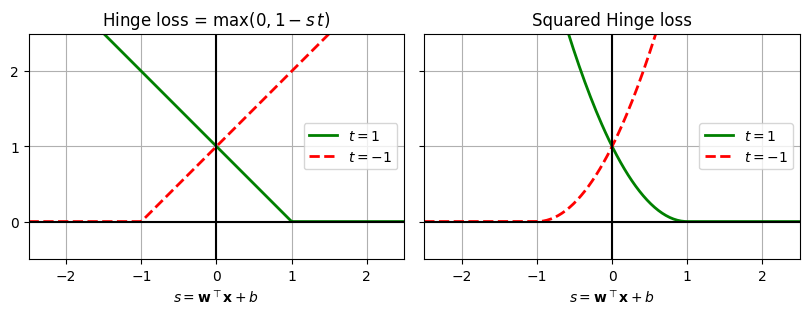

In [12]:
fig, axs = plt.subplots(1, 2, sharey=True, figsize=(8.2, 3))

for ax, loss_pos, loss_neg, title in zip(
    axs,
    (hinge_pos, hinge_pos**2),
    (hinge_neg, hinge_neg**2),
    titles
):
    ax.plot(s, loss_pos, "g-", linewidth=2, label="$t=1$")
    ax.plot(s, loss_neg, "r--", linewidth=2, label="$t=-1$")
    ax.grid(True)
    ax.axhline(0, color="k")
    ax.axvline(0, color="k")
    ax.set_xlabel(r"$s = \mathbf{w}^\top \mathbf{x} + b$")
    ax.axis([-2.5, 2.5, -0.5, 2.5])
    ax.legend(loc="center right")
    ax.set_title(title)
    ax.set_yticks(np.arange(0, 2.5, 1))
    ax.set_aspect("equal")
save_fig("hinge_plot")
plt.show()

---

## Project notes and next steps
Tune C and kernel parameters with cross-validation, scale features inside a pipeline, and report test-set metrics instead of relying only on visual boundaries.

## Topics / hashtags
#MachineLearning #SVM #SupportVectorMachines #Classification #ScikitLearn #Python #ModelSelection #DataScience

## Feedback
Suggestions for improving the analysis, evaluation, or visualizations are welcome.
